# What do protein language models know about moonlighting?

**Moonlighting proteins** carry out two or more unrelated functions with a single polypeptide chain. They are not
splice variants, gene fusions or promiscuous enzymes. Textbook cases include glycolytic **enolase**, which is also a
plasminogen receptor on bacterial surfaces and a transcriptional repressor (MBP-1). **GAPDH** also acts in apoptosis
and DNA repair, and lens **crystallins** are also active enzymes. Moonlighting is usually found by accident, so the
known set is small and biased, and a sequence-only predictor would be very useful.

This notebook asks what frozen, general-purpose **protein language model (pLM) embeddings** encode about
moonlighting, using a small curated benchmark (345 proteins). It asks four questions:

| | Question | Section |
|---|---|---|
| **Q1** | Which pLM represents moonlighting best, and does model scale help? | §3–4 |
| **Q2** | Where in the network does the signal live? | §4 |
| **Q3** | Is the signal genuine? Does it survive homology-aware splits, and does it beat trivial baselines? | §3 |
| **Q4** | Is the model detecting *moonlighting*, or detecting *the kind of protein that happens to be labelled moonlighting*? | §5–6 |

**Design choices, kept deliberately simple**
* One classifier throughout: a **linear probe** (standardised L2 logistic regression, with C tuned in an inner CV).
  A linear probe measures what the representation already encodes, without letting a flexible classifier build
  the features itself. With 345 examples it is also the honest choice.
* Frozen **5 × 5-fold CV**, run twice: once with random folds, and once with **homology-grouped** folds, where no
  test protein shares ≥30 % identity (≥50 % coverage) with any training protein.
* Nine pLMs from four families, plus three non-pLM baselines. The pLMs are ESM-2 (8M → 3B), ESM C (300M, 600M),
  ProtT5-XL and Ankh-large.

> Embeddings are pre-computed by `scripts/embed.py` (GPU, ~10 min for all models) and ship with the repo,
> so this notebook runs on a laptop CPU in a few minutes.

In [1]:
import json, pathlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy import stats
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef
warnings.filterwarnings("ignore", category=UserWarning)

EMB, FIG, RES = pathlib.Path("embeddings"), pathlib.Path("figures"), pathlib.Path("results")
FIG.mkdir(exist_ok=True); RES.mkdir(exist_ok=True)

# colour = identity: one hue per model family, one per class (palette validated for colour-vision deficiency)
FAMILY_COLOR = {"ESM-2": "#2a78d6", "ESM C": "#eb6834", "ProtT5": "#1baf7a", "Ankh": "#eda100",
                "baseline": "#8a8985"}
CLASS_COLOR  = {1: "#e34948", 0: "#4a3aa7"}
CLASS_NAME   = {1: "Moonlighting", 0: "Non-moonlighting"}
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "axes.labelcolor": "#0b0b0b",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "legend.frameon": False})

## 1 · Data

`scripts/prepare_data.py` curates the raw spreadsheets (`data/raw/`) into a frozen benchmark:

* **3 accessions appear in both class files** (O75821, P43274, P69786). They are removed rather than assigned a
  guessed label.
* Duplicate sequences are removed. No sequence is shorter than 30 aa. **24 proteins exceed 1,022 residues**, and
  these are embedded with overlapping windows instead of being truncated.
* An all-vs-all Smith–Waterman alignment defines homology clusters (≥30 % identity over ≥50 % of the shorter
  sequence). These clusters drive the grouped CV folds.

UniProt annotations (`scripts/fetch_uniprot.py`) are used **only to interpret** the models, never as model input.

In [2]:
df  = pd.read_csv("data/clean.csv")
ann = pd.read_csv("data/uniprot_annotations.csv").set_index("Entry").loc[df.Entry].reset_index()
audit = json.load(open("results/qc_audit.json"))
folds = {k: np.array(v) for k, v in json.load(open("data/folds.json")).items()}
y = df.label.values

kw = ann.Keywords.fillna("")
df["name"]      = ann["Protein names"].str.split(" \(").str[0]
df["organism"]  = ann.Organism.str.split(" \(").str[0]
df["enzyme"]    = ann["EC number"].notna()
df["membrane"]  = kw.str.contains("Transmembrane")
df["category"]  = np.select([df.membrane, df.enzyme], ["membrane", "soluble enzyme"], "soluble non-enzyme")

print(f"{len(df)} proteins: {y.sum()} moonlighting / {(1 - y).sum()} non-moonlighting "
      f"(prevalence {y.mean():.2f})")
print(f"{audit['n_clusters']} homology clusters -> only {len(df) - audit['n_clusters']} proteins "
      f"have a close homologue in the set, so redundancy is low")

345 proteins: 212 moonlighting / 133 non-moonlighting (prevalence 0.61)
320 homology clusters -> only 25 proteins have a close homologue in the set, so redundancy is low


<>:8: SyntaxWarning: invalid escape sequence '\('
<>:9: SyntaxWarning: invalid escape sequence '\('
<>:8: SyntaxWarning: invalid escape sequence '\('
<>:9: SyntaxWarning: invalid escape sequence '\('
/tmp/ipykernel_198086/3502121377.py:8: SyntaxWarning: invalid escape sequence '\('
  df["name"]      = ann["Protein names"].str.split(" \(").str[0]
/tmp/ipykernel_198086/3502121377.py:9: SyntaxWarning: invalid escape sequence '\('
  df["organism"]  = ann.Organism.str.split(" \(").str[0]


### A first look reveals a strong compositional bias

Before any modelling, it is worth asking what else separates the two classes.

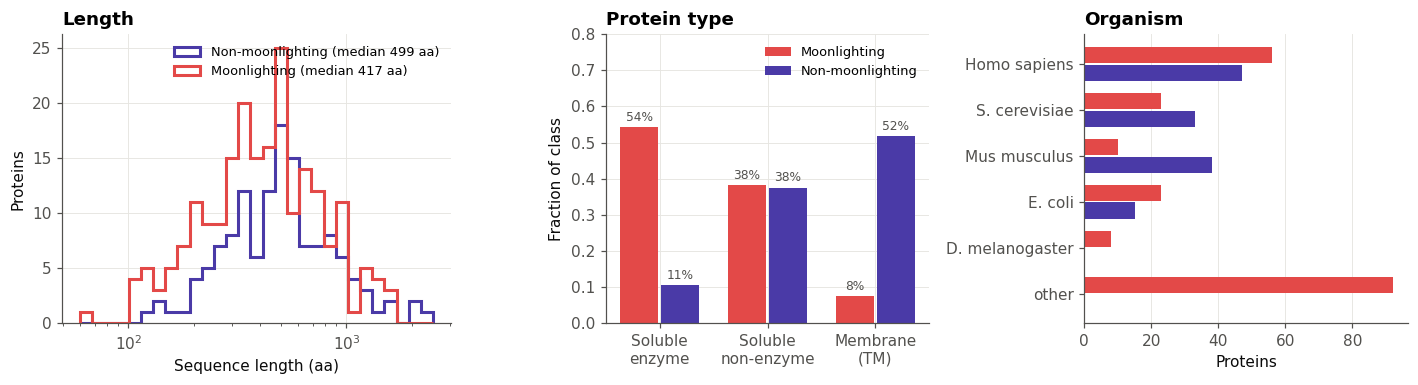

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1.2, 1, 1]})

ax = axes[0]
bins = np.logspace(np.log10(60), np.log10(2500), 30)
for c in (0, 1):
    ax.hist(df.length[y == c], bins=bins, histtype="step", lw=2, color=CLASS_COLOR[c],
            label=f"{CLASS_NAME[c]} (median {int(df.length[y == c].median())} aa)")
ax.set_xscale("log"); ax.set_xlabel("Sequence length (aa)"); ax.set_ylabel("Proteins")
ax.set_title("Length", loc="left", fontweight="bold"); ax.legend(fontsize=8.5)

ax = axes[1]
cats = ["soluble enzyme", "soluble non-enzyme", "membrane"]
frac = pd.crosstab(df.category, df.label, normalize="columns").loc[cats]
x = np.arange(len(cats)); w = 0.38
for i, c in enumerate((1, 0)):
    b = ax.bar(x + (i - .5) * w, frac[c], w - 0.03, color=CLASS_COLOR[c], label=CLASS_NAME[c])
    ax.bar_label(b, fmt=lambda v: f"{v:.0%}", fontsize=8, padding=2, color="#52514e")
ax.set_xticks(x, ["Soluble\nenzyme", "Soluble\nnon-enzyme", "Membrane\n(TM)"])
ax.set_ylabel("Fraction of class"); ax.set_ylim(0, 0.8); ax.legend(fontsize=8.5)
ax.set_title("Protein type", loc="left", fontweight="bold")

ax = axes[2]
top = df.organism.value_counts().index[:5]
org = pd.crosstab(df.organism.where(df.organism.isin(top), "other"), df.label).loc[list(top) + ["other"]]
yy = np.arange(len(org))[::-1]
for i, c in enumerate((1, 0)):
    ax.barh(yy + (0.5 - i) * w, org[c], w - 0.03, color=CLASS_COLOR[c])
ax.set_yticks(yy, [o.replace("Saccharomyces", "S.").replace("Escherichia", "E.")
                   .replace("Drosophila", "D.") for o in org.index])
ax.set_xlabel("Proteins"); ax.set_title("Organism", loc="left", fontweight="bold"); ax.grid(axis="y", visible=False)

fig.tight_layout(); fig.savefig(FIG / "fig1_dataset.png", bbox_inches="tight"); plt.show()

In [4]:
shortcut = df.enzyme.astype(int) - df.membrane.astype(int)       # +1 soluble enzyme ... -1 membrane protein
print(f"AUROC of a 2-bit annotation rule (enzyme? transmembrane?) : {roc_auc_score(y, shortcut):.3f}")

AUROC of a 2-bit annotation rule (enzyme? transmembrane?) : 0.804


**The two classes differ in *what kind of protein* they contain.** Most moonlighting proteins here are soluble,
cytosolic enzymes, the classic metabolic and chaperone moonlighters. Half of the non-moonlighting set is made of
**transmembrane transporters and receptors**. A rule that knows only *is it an enzyme?* and *is it
transmembrane?* already reaches **AUROC ≈ 0.80** without reading the sequence at all.

This does not make the dataset wrong. Moonlighting really is enriched among ancient, abundant, cytosolic enzymes,
which have had long evolutionary time and high local concentrations for second functions to arise. It does,
however, set the bar that any claim of "predicting moonlighting" must clear. Section 5 returns to this.

## 2 · Representations

Each pLM maps a sequence to per-residue vectors. We **mean-pool** the final layer (all layers are also stored for
§4) into one vector per protein. Proteins longer than 1,000 residues are embedded in overlapping windows of
1,000 residues (stride 500), and the per-residue vectors are averaged across overlaps before pooling.

The **baselines** are:

* `length`: log sequence length, a single number.
* `handcrafted`: amino-acid composition (20) + dipeptide composition (400) + 8 ProtParam descriptors.
* `nearest homologue`: the classic "BLAST it" approach. The score is the maximum identity to a *moonlighting*
  training protein minus the maximum identity to a *non-moonlighting* one.

In [5]:
PLMS = {  # name: family
    "esm2_8M": "ESM-2", "esm2_35M": "ESM-2", "esm2_150M": "ESM-2", "esm2_650M": "ESM-2", "esm2_3B": "ESM-2",
    "esmc_300M": "ESM C", "esmc_600M": "ESM C", "prott5_xl": "ProtT5", "ankh_large": "Ankh"}
BASELINES = ["length", "handcrafted"]

X    = {m: np.load(EMB / f"{m}.npy") for m in BASELINES + list(PLMS)}
meta = pd.DataFrame([json.load(open(EMB / f"{m}.json")) for m in PLMS]).set_index("model")
meta["family"] = pd.Series(PLMS)
meta["params (M)"] = (meta.n_params / 1e6).round(0).astype(int)
meta[["family", "checkpoint", "params (M)", "dim", "n_layers", "seconds"]]

,family,checkpoint,params (M),dim,n_layers,seconds
model,,,,,,
esm2_8M,ESM-2,facebook/esm2_t6_8M_UR50D,8,320,6,5
esm2_35M,ESM-2,facebook/esm2_t12_35M_UR50D,34,480,12,10
esm2_150M,ESM-2,facebook/esm2_t30_150M_UR50D,148,640,30,24
esm2_650M,ESM-2,facebook/esm2_t33_650M_UR50D,651,1280,33,25
esm2_3B,ESM-2,facebook/esm2_t36_3B_UR50D,2835,2560,36,48
esmc_300M,ESM C,esmc_300m,333,960,30,36
esmc_600M,ESM C,esmc_600m,575,1152,36,57
prott5_xl,ProtT5,Rostlab/prot_t5_xl_half_uniref50-enc,1208,1024,24,38
ankh_large,Ankh,ElnaggarLab/ankh-large,1152,1536,48,81


## 3 · Benchmark

Every representation goes through the same code. For each of the 50 train/test splits (2 regimes × 5 repeats × 5
folds), we fit `StandardScaler → LogisticRegressionCV` on the training fold. The inner 3-fold CV picks C from
10⁻⁴…1, with class-balanced weights. We then score the held-out fold on:

* **AUROC**: threshold-free ranking quality (primary metric).
* **AUPRC**: precision–recall. The no-skill line equals the prevalence, 0.61.
* **MCC**: at the default 0.5 threshold, robust to class imbalance.

In [6]:
def probe():
    return make_pipeline(StandardScaler(),
                         LogisticRegressionCV(Cs=np.logspace(-4, 0, 9), cv=3, scoring="roc_auc",
                                              class_weight="balanced", max_iter=5000))

def score_fold(Xm, split, k, target=y):
    te = folds[split] == k
    p = probe().fit(Xm[~te], target[~te]).predict_proba(Xm[te])[:, 1]
    return p, te

def metrics(t, p, thr=0.5):
    return dict(auroc=roc_auc_score(t, p), auprc=average_precision_score(t, p),
                mcc=matthews_corrcoef(t, p > thr))

def evaluate(Xm, target=y, splits=folds):
    # 5x5 CV for every split in `splits` -> per-fold metrics + out-of-fold predictions
    out = Parallel(n_jobs=-1)(delayed(score_fold)(Xm, s, k, target) for s in splits for k in range(5))
    rows, oof = [], {s: np.zeros(len(target)) for s in splits}
    for (p, te), (s, k) in zip(out, [(s, k) for s in splits for k in range(5)]):
        oof[s][te] = p
        rows.append(dict(split=s, regime=s.split("_")[0], fold=k, **metrics(target[te], p)))
    return pd.DataFrame(rows), oof

# nearest-homologue baseline: no fitting, just label transfer by Smith-Waterman identity
PID = np.load("data/pairwise_identity.npy").astype(float); np.fill_diagonal(PID, 0)
def nearest_homologue():
    rows, oof = [], {s: np.zeros(len(y)) for s in folds}
    for s in folds:
        for k in range(5):
            te = folds[s] == k
            sim = PID[np.ix_(te, ~te)]; ytr = y[~te]
            p = sim[:, ytr == 1].max(1) - sim[:, ytr == 0].max(1)
            oof[s][te] = p
            rows.append(dict(split=s, regime=s.split("_")[0], fold=k, **metrics(y[te], p, thr=0)))
    return pd.DataFrame(rows), oof

In [7]:
results, OOF = [], {}
for m in BASELINES + list(PLMS):
    r, OOF[m] = evaluate(X[m])
    results.append(r.assign(model=m))
r, OOF["nearest_homologue"] = nearest_homologue()
results.append(r.assign(model="nearest_homologue"))

res = pd.concat(results, ignore_index=True)
res["family"] = res.model.map(PLMS).fillna("baseline")
res.to_csv(RES / "benchmark_folds.csv", index=False)

summary = (res.groupby(["model", "regime"])[["auroc", "auprc", "mcc"]].agg(["mean", "std"])
              .unstack("regime"))
table = pd.DataFrame({
    f"{met.upper()} ({reg})": summary[(met, "mean", reg)].map("{:.3f}".format) + " ± "
                              + summary[(met, "std", reg)].map("{:.3f}".format)
    for met in ["auroc", "auprc", "mcc"] for reg in ["grouped", "random"]})
order = summary[("auroc", "mean", "grouped")].sort_values(ascending=False).index
table = table.loc[order, [c for c in table if "grouped" in c] + ["AUROC (random)"]]
table.to_csv(RES / "benchmark_summary.csv"); table

,AUROC (grouped),AUPRC (grouped),MCC (grouped),AUROC (random)
model,,,,
ankh_large,0.893 ± 0.048,0.931 ± 0.036,0.654 ± 0.105,0.893 ± 0.040
esm2_3B,0.881 ± 0.040,0.925 ± 0.033,0.612 ± 0.097,0.878 ± 0.042
esm2_150M,0.878 ± 0.039,0.920 ± 0.031,0.617 ± 0.092,0.876 ± 0.038
esm2_650M,0.878 ± 0.038,0.920 ± 0.034,0.604 ± 0.094,0.873 ± 0.047
esm2_35M,0.870 ± 0.036,0.908 ± 0.035,0.622 ± 0.089,0.872 ± 0.040
prott5_xl,0.869 ± 0.040,0.926 ± 0.027,0.606 ± 0.089,0.870 ± 0.047
esm2_8M,0.868 ± 0.040,0.907 ± 0.036,0.588 ± 0.093,0.872 ± 0.032
esmc_600M,0.853 ± 0.043,0.909 ± 0.035,0.566 ± 0.095,0.853 ± 0.043
esmc_300M,0.853 ± 0.045,0.910 ± 0.034,0.559 ± 0.096,0.854 ± 0.044


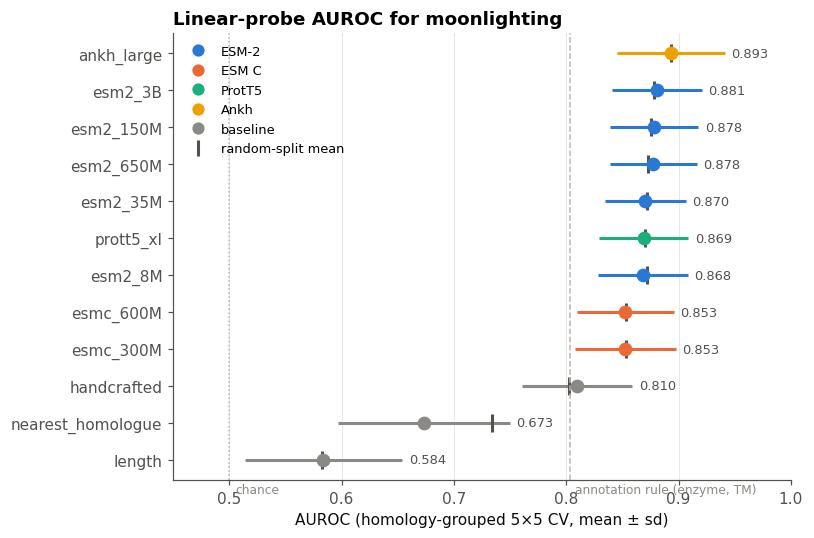

In [8]:
g = res[res.regime == "grouped"].groupby("model").auroc.agg(["mean", "std"])
rnd = res[res.regime == "random"].groupby("model").auroc.mean()
g = g.loc[order[::-1]]
fig, ax = plt.subplots(figsize=(7.5, 5))
yy = np.arange(len(g))
for i, (m, row) in enumerate(g.iterrows()):
    col = FAMILY_COLOR[PLMS.get(m, "baseline")]
    ax.errorbar(row["mean"], i, xerr=row["std"], fmt="o", ms=8, color=col, ecolor=col, elinewidth=2, capsize=0)
    ax.plot(rnd[m], i, "|", ms=12, mew=2, color="#52514e")
    ax.text(row["mean"] + row["std"] + 0.006, i, f"{row['mean']:.3f}", va="center", fontsize=8.5, color="#52514e")
ax.axvline(0.5, color="#b9b8b2", lw=1, ls=":"); ax.text(0.505, -0.9, "chance", fontsize=8, color="#8a8985")
ax.axvline(roc_auc_score(y, shortcut), color="#b9b8b2", lw=1, ls="--")
ax.text(roc_auc_score(y, shortcut) + 0.004, -0.9, "annotation rule (enzyme, TM)", fontsize=8, color="#8a8985")
ax.set_yticks(yy, g.index); ax.set_xlabel("AUROC (homology-grouped 5×5 CV, mean ± sd)")
ax.set_xlim(0.45, 1.0); ax.grid(axis="y", visible=False)
handles = [plt.Line2D([], [], marker="o", ls="", color=c, ms=7, label=f) for f, c in FAMILY_COLOR.items()]
handles += [plt.Line2D([], [], marker="|", ls="", color="#52514e", ms=10, mew=2, label="random-split mean")]
ax.legend(handles=handles, loc="upper left", fontsize=8.5)
ax.set_title("Linear-probe AUROC for moonlighting", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig2_benchmark.png", bbox_inches="tight"); plt.show()

**Is the best pLM really better than the others?** Folds from repeated CV share training data, so a naive paired
t-test is over-confident. We use the **Nadeau–Bengio corrected resampled t-test**, which inflates the variance by
n_test/n_train.

In [9]:
def corrected_ttest(a, b, n_train=276, n_test=69):
    d = np.asarray(a) - np.asarray(b); n = len(d)
    t = d.mean() / np.sqrt((1 / n + n_test / n_train) * d.var(ddof=1))
    return d.mean(), 2 * stats.t.sf(abs(t), n - 1)

gr = res[res.regime == "grouped"].pivot_table(index=["split", "fold"], columns="model", values="auroc")
best = g["mean"].idxmax()
cmp = pd.DataFrame([dict(zip(["ΔAUROC", "p"], corrected_ttest(gr[best], gr[m])), model=m)
                    for m in gr if m != best]).set_index("model").sort_values("ΔAUROC")
print(f"best representation: {best}\n")
cmp.style.format({"ΔAUROC": "{:+.3f}", "p": "{:.3g}"})

best representation: ankh_large



,ΔAUROC,p
model,,
esm2_3B,+0.012,0.395
esm2_150M,+0.015,0.405
esm2_650M,+0.015,0.325
esm2_35M,+0.023,0.14
prott5_xl,+0.024,0.0591
esm2_8M,+0.025,0.143
esmc_600M,+0.040,0.0344
esmc_300M,+0.040,0.00856
handcrafted,+0.083,0.00746


**What the benchmark says**

* **Every pLM beats every non-pLM baseline.** The nine pLMs span AUROC 0.85–0.89. Handcrafted composition features
  reach 0.81, and the best pLM beats them by +0.08 AUROC (p ≈ 0.007, corrected test).
* **Homology alone is weak.** Nearest-homologue label transfer reaches only 0.67. Most proteins here have no close
  relative in the set, so the pLMs must be generalising *beyond* sequence similarity.
* **Homology-grouped CV is a working control.** The grouped split costs the pLMs nothing (random-split ticks sit on
  the dots). It costs the homology baseline 0.06 AUROC (0.73 → 0.67), which is exactly where leakage *should* show
  up. Redundancy in this benchmark is low, so the pLM numbers are not inflated by near-duplicates.
* **The pLMs are statistically indistinguishable, with one exception.** Ankh-large ranks first, but its lead over
  ESM-2 and ProtT5 (+0.01–0.02) is within fold-to-fold noise. Only the ESM C *final layers* are reliably worse
  (p < 0.05), and §4 shows why.

## 4 · Scale and depth

**Scale.** Does a bigger model know more? The ESM-2 family gives a clean ladder from 8M to 3B parameters trained
on the same data.

**Depth.** Final-layer embeddings are the default, but the last layers of a masked-LM are tuned to predict
amino-acid identity. Functional and structural information often peaks in *intermediate* layers. We probe every
layer of the largest model in each family, using grouped CV.

In [10]:
# all-layer embeddings (~200 MB) are not in git: regenerate with scripts/embed.py, else use the cached result
LAYER_MODELS = ["esm2_3B", "esmc_600M", "prott5_xl", "ankh_large"]
grouped_splits = {s: v for s, v in folds.items() if s.startswith("grouped")}
if all((EMB / "layers" / f"{m}.npy").exists() for m in LAYER_MODELS):
    layer_res = []
    for m in LAYER_MODELS:
        H = np.load(EMB / "layers" / f"{m}.npy").astype(np.float32)          # (N, layers, d), z-scored
        off, n = meta.loc[m, "first_layer_index"], meta.loc[m, "n_layers"]
        for l in range(H.shape[1]):
            r, _ = evaluate(H[:, l], splits=grouped_splits)
            layer_res.append(dict(model=m, layer=l + off, depth=(l + off) / n, auroc=r.auroc.mean(), sd=r.auroc.std()))
    layer_res = pd.DataFrame(layer_res); layer_res.to_csv(RES / "layerwise.csv", index=False)
else:
    print("layer embeddings not found -> loading cached results/layerwise.csv")
    layer_res = pd.read_csv(RES / "layerwise.csv")
layer_res.loc[layer_res.groupby("model").auroc.idxmax()].set_index("model").round(3)

,layer,depth,auroc,sd
model,,,,
ankh_large,48,1.000,0.893,0.048
esm2_3B,16,0.444,0.890,0.038
esmc_600M,21,0.583,0.898,0.045
prott5_xl,13,0.542,0.897,0.036


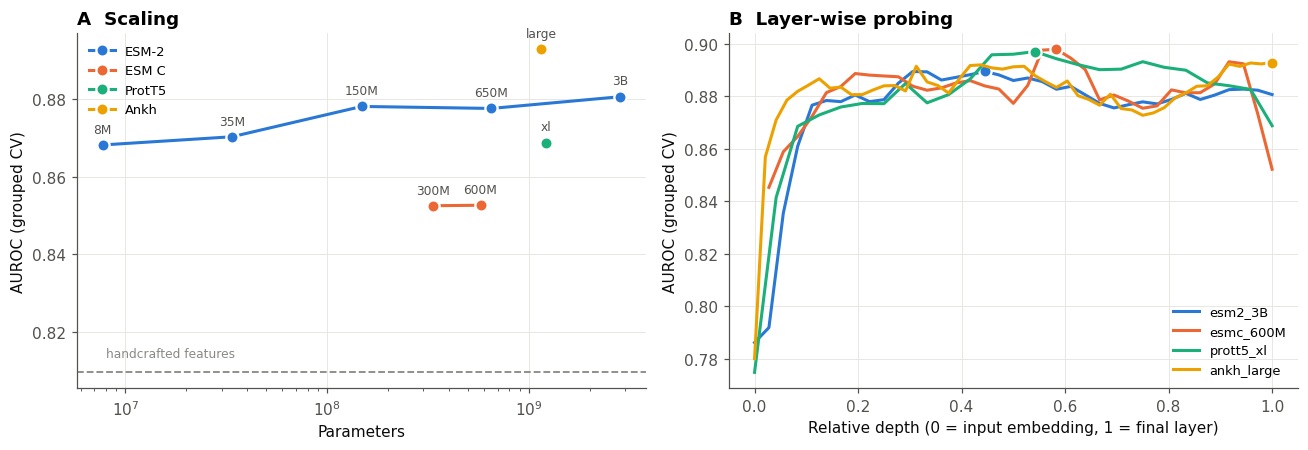

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

ax = axes[0]
gm = res[res.regime == "grouped"].groupby("model").auroc.agg(["mean", "std"])
for fam in ["ESM-2", "ESM C", "ProtT5", "Ankh"]:
    ms = [m for m in PLMS if PLMS[m] == fam]
    xs, ys, es = meta.loc[ms, "n_params"], gm.loc[ms, "mean"], gm.loc[ms, "std"]
    ax.plot(xs, ys, "-o", color=FAMILY_COLOR[fam], lw=2, ms=8, label=fam, mec="white", mew=1.5)
    for m, xv, yv in zip(ms, xs, ys):
        ax.annotate(m.split("_")[1], (xv, yv), xytext=(0, 8), textcoords="offset points",
                    ha="center", fontsize=8, color="#52514e")
ax.axhline(gm.loc["handcrafted", "mean"], color=FAMILY_COLOR["baseline"], ls="--", lw=1.2)
ax.text(8e6, gm.loc["handcrafted", "mean"] + 0.004, "handcrafted features", fontsize=8, color="#8a8985")
ax.set_xscale("log"); ax.set_xlabel("Parameters"); ax.set_ylabel("AUROC (grouped CV)")
ax.set_title("A  Scaling", loc="left", fontweight="bold"); ax.legend(loc="upper left", fontsize=8.5)

ax = axes[1]
for m, fam in [("esm2_3B", "ESM-2"), ("esmc_600M", "ESM C"), ("prott5_xl", "ProtT5"), ("ankh_large", "Ankh")]:
    d = layer_res[layer_res.model == m]
    ax.plot(d.depth, d.auroc, "-", lw=2, color=FAMILY_COLOR[fam], label=m)
    b = d.loc[d.auroc.idxmax()]
    ax.plot(b.depth, b.auroc, "o", ms=8, color=FAMILY_COLOR[fam], mec="white", mew=1.5)
ax.set_xlabel("Relative depth (0 = input embedding, 1 = final layer)"); ax.set_ylabel("AUROC (grouped CV)")
ax.set_title("B  Layer-wise probing", loc="left", fontweight="bold"); ax.legend(loc="lower right", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "fig3_scale_depth.png", bbox_inches="tight"); plt.show()

**Scale buys almost nothing.** A 350-fold increase in ESM-2 parameters (8M → 3B) moves AUROC from 0.868 to 0.881.
Whatever distinguishes moonlighters in these data is already captured by the smallest model. This fits the
confounder analysis below: coarse properties such as "membrane vs soluble" and "enzyme vs not" are learned early and
cheaply.

**Depth matters more than size.** For ESM C, ProtT5 and ESM-2 the best layer sits at **45–60 % depth**, not at the
output:

| model | final layer | best layer (depth) | gain |
|---|---|---|---|
| ESM C 600M | 0.852 | **0.898** (L21, 58 %) | +0.046 |
| ProtT5-XL | 0.869 | **0.897** (L13, 54 %) | +0.028 |
| ESM-2 3B | 0.881 | 0.890 (L16, 44 %) | +0.009 |
| Ankh-large | **0.893** | final | — |

The final layers of masked-LM encoders specialise in reconstructing residue identity. More abstract,
function-relevant features peak mid-network. At their best layers all four families converge on AUROC 0.89–0.90,
so the ESM C "deficit" in §3 is an artefact of taking the last layer. (Best layers were picked on the same CV folds,
so these numbers are mildly optimistic. The *shape* of the curves is the robust finding.) **Practical rule: for
function-level probing, try intermediate layers before trying bigger models.**

## 5 · What is the embedding space organised by?

We project the best final-layer embedding to 2D with UMAP and colour it twice: by moonlighting label, and by the
protein-type categories from §1. If the pLM geometry mainly follows protein type, the two maps will look alike.

2026-09-29 22:48:07.099637: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


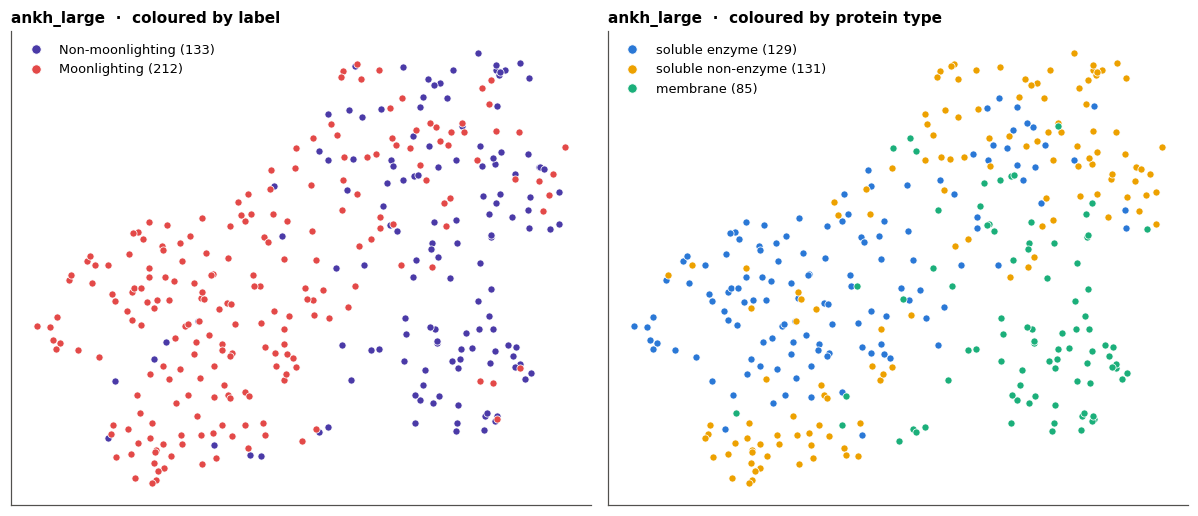

In [12]:
import umap
Z = umap.UMAP(n_neighbors=15, min_dist=0.3, metric="cosine", random_state=0).fit_transform(
        StandardScaler().fit_transform(X[best]))

CAT_COLOR = {"soluble enzyme": "#2a78d6", "soluble non-enzyme": "#eda100", "membrane": "#1baf7a"}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, key, cmap, title in [(axes[0], "label", {c: CLASS_COLOR[c] for c in (0, 1)}, "coloured by label"),
                             (axes[1], "category", CAT_COLOR, "coloured by protein type")]:
    for lvl, col in cmap.items():
        s = df[key] == lvl
        ax.scatter(Z[s, 0], Z[s, 1], s=22, color=col, edgecolor="white", lw=0.5,
                   label=CLASS_NAME.get(lvl, lvl) + f" ({s.sum()})")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_title(f"{best}  ·  {title}", loc="left", fontweight="bold", fontsize=10)
    ax.legend(fontsize=8.5, loc="best", markerscale=1.3)
fig.tight_layout(); fig.savefig(FIG / "fig4_umap.png", bbox_inches="tight"); plt.show()

The pLM separates membrane proteins from soluble ones, and enzymes from non-enzymes, almost perfectly. These are
properties that pLMs are known to capture well. We can check this directly by probing for the confounders
themselves:

In [13]:
conf = {}
for tgt in ["enzyme", "membrane"]:
    r, _ = evaluate(X[best], target=df[tgt].values.astype(int), splits=grouped_splits)
    conf[tgt] = r.auroc.mean()
r, _ = evaluate(X[best], splits=grouped_splits)
conf["moonlighting"] = r.auroc.mean()
pd.Series(conf, name=f"{best} probe AUROC").round(3).to_frame()

,ankh_large probe AUROC
enzyme,0.909
membrane,0.959
moonlighting,0.893


## 6 · The key test: does the signal survive *within* protein types?

A model that only detects "soluble enzyme" would rank well across the whole set but **fail within each protein
type**. The same logic applies to organism: non-moonlighting proteins come from only four species, so we
also score **human proteins alone**. We therefore take the out-of-fold predictions (grouped CV, averaged over the 5 repeats) and compute AUROC
**inside each stratum**, with 95 % bootstrap CIs.

In short, this asks whether, **among soluble enzymes alone**, the model can still tell moonlighters from
non-moonlighters.

In [14]:
def oof_mean(m):
    return np.mean([OOF[m][s] for s in grouped_splits], axis=0)

def boot_auc(t, p, n=2000, seed=0):
    rng, aucs = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(t), len(t))
        if 0 < t[i].sum() < len(i):
            aucs.append(roc_auc_score(t[i], p[i]))
    return roc_auc_score(t, p), *np.percentile(aucs, [2.5, 97.5])

strata = {"all proteins": np.ones(len(df), bool), "soluble (non-TM)": ~df.membrane.values,
          "soluble enzymes": (df.category == "soluble enzyme").values,
          "soluble non-enzymes": (df.category == "soluble non-enzyme").values,
          "human only": (df.organism == "Homo sapiens").values}
compare = [best, "handcrafted", "length"]
rows = []
for sname, s in strata.items():
    for m in compare:
        auc, lo, hi = boot_auc(y[s], oof_mean(m)[s])
        rows.append(dict(stratum=sname, model=m, auroc=auc, lo=lo, hi=hi, n_pos=y[s].sum(), n_neg=(1 - y[s]).sum()))
strat = pd.DataFrame(rows); strat.to_csv(RES / "stratified_auroc.csv", index=False)
strat.pivot(index="stratum", columns="model", values="auroc").loc[list(strata)][compare].round(3)

model,ankh_large,handcrafted,length
stratum,,,
all proteins,0.893,0.809,0.575
soluble (non-TM),0.869,0.727,0.561
soluble enzymes,0.799,0.554,0.501
soluble non-enzymes,0.836,0.747,0.628
human only,0.843,0.790,0.503


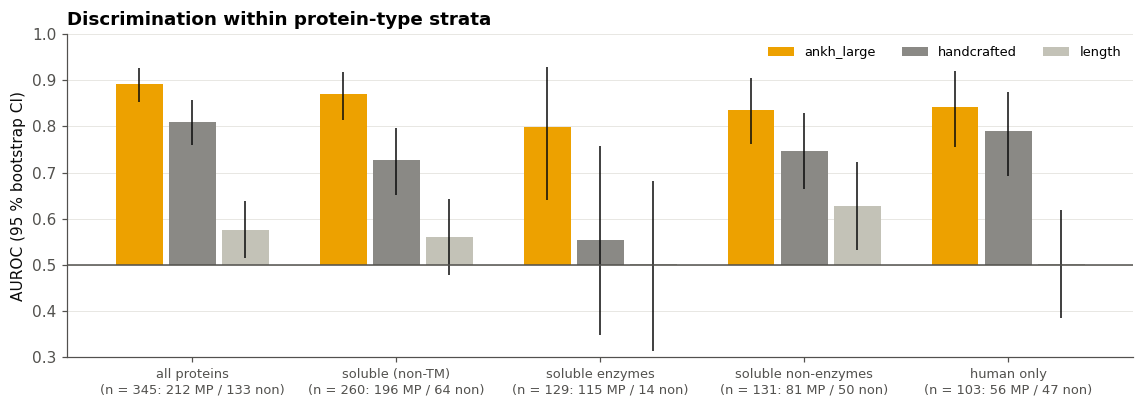

In [15]:
fig, ax = plt.subplots(figsize=(10.5, 3.8))
cols = {best: FAMILY_COLOR[PLMS[best]], "handcrafted": "#8a8985", "length": "#c3c2b7"}
w = 0.26
for j, m in enumerate(compare):
    d = strat[strat.model == m].set_index("stratum").loc[list(strata)]
    xs = np.arange(len(d)) + (j - 1) * w
    ax.bar(xs, d.auroc - 0.5, w - 0.03, bottom=0.5, color=cols[m], label=m)
    ax.errorbar(xs, d.auroc, yerr=[d.auroc - d.lo, d.hi - d.auroc], fmt="none", ecolor="#0b0b0b", elinewidth=1)
labels = [f"{k}\n(n = {int(v.sum())}: {int(y[v].sum())} MP / {int((1 - y[v]).sum())} non)" for k, v in strata.items()]
ax.set_xticks(np.arange(len(strata)), labels, fontsize=8.5)
ax.axhline(0.5, color="#52514e", lw=1); ax.set_ylim(0.3, 1.0); ax.set_ylabel("AUROC (95 % bootstrap CI)")
ax.legend(fontsize=8.5, loc="upper right", ncol=3); ax.grid(axis="x", visible=False)
ax.set_title("Discrimination within protein-type strata", loc="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG / "fig5_stratified.png", bbox_inches="tight"); plt.show()

**This is the central result.**

* **Handcrafted features were mostly detecting protein type.** Their AUROC falls from 0.81 overall to 0.73 among
  soluble proteins, and to **chance (0.55) among soluble enzymes**.
* **The pLM signal largely survives stratification.** Ankh-large reaches 0.87 [0.81–0.92] among soluble proteins,
  0.84 [0.76–0.90] among soluble non-enzymes, and 0.80 [0.64–0.93] among soluble enzymes (only
  14 negatives, hence the wide CI). Among **human proteins only**, where the organism confound is removed, it reaches
  0.84 [0.76–0.92] (n = 56 MP / 47 non).
* So the pLM **does** use the shortcut, since it encodes membrane status (AUROC 0.96) and enzyme status (0.91) almost
  perfectly. But part of its signal is **orthogonal to protein type**, and that part is what classical features
  cannot see.

The honest headline is therefore not "pLMs predict moonlighting with AUROC 0.89". It is **"pLMs retain AUROC
≈ 0.8–0.87 once the obvious protein-type shortcut is controlled for, while composition features do not."**

## 7 · Reading the model's mistakes as biology

"Non-moonlighting" here really means *not known to moonlight*. Moonlighting is discovered by accident, so some
negatives are surely unrecognised moonlighters. The most confident "false positives" are therefore **hypotheses**,
not just errors.

In [16]:
df["p_moon"] = oof_mean(best)
cols_show = ["Entry", "name", "organism", "category", "length", "p_moon"]
print("Highest-scoring NON-moonlighting proteins (candidate undiscovered moonlighters):")
display(df[y == 0].nlargest(10, "p_moon")[cols_show].style.format({"p_moon": "{:.2f}"}).hide(axis="index"))
print("Lowest-scoring MOONLIGHTING proteins (moonlighters the pLM cannot see):")
display(df[y == 1].nsmallest(10, "p_moon")[cols_show].style.format({"p_moon": "{:.2f}"}).hide(axis="index"))
df[["Entry", "name", "organism", "category", "label", "p_moon"]].to_csv(RES / f"oof_predictions_{best}.csv", index=False)

Highest-scoring NON-moonlighting proteins (candidate undiscovered moonlighters):


Entry,name,organism,category,length,p_moon
P47813,"Eukaryotic translation initiation factor 1A, X-chromosomal",Homo sapiens,soluble non-enzyme,144,0.89
P47176,"Branched-chain-amino-acid aminotransferase, cytosolic",Saccharomyces cerevisiae,soluble enzyme,376,0.81
Q9D7P7,Chloride intracellular channel protein 3,Mus musculus,membrane,237,0.81
P69797,PTS system mannose-specific EIIAB component,Escherichia coli,soluble enzyme,323,0.78
Q9H492,Microtubule-associated protein 1 light chain 3 alpha,Homo sapiens,soluble non-enzyme,121,0.74
P00724,Invertase 2,Saccharomyces cerevisiae,soluble enzyme,532,0.72
P04395,DNA-3-methyladenine glycosylase 2,Escherichia coli,soluble enzyme,282,0.65
P38624,Proteasome subunit beta type-1,Saccharomyces cerevisiae,soluble enzyme,215,0.65
Q15560,Transcription elongation factor A protein 2,Homo sapiens,soluble non-enzyme,299,0.58
Q02486,"ARS-binding factor 2, mitochondrial",Saccharomyces cerevisiae,soluble non-enzyme,183,0.58


Lowest-scoring MOONLIGHTING proteins (moonlighters the pLM cannot see):


Entry,name,organism,category,length,p_moon
Q5BJF6,Outer dense fiber protein 2,Homo sapiens,soluble non-enzyme,829,0.13
Q04637,Eukaryotic translation initiation factor 4 gamma 1,Homo sapiens,soluble non-enzyme,1599,0.19
P47992,Lymphotactin,Homo sapiens,soluble non-enzyme,114,0.19
Q9H307,Pinin,Homo sapiens,soluble non-enzyme,717,0.21
P02730,Band 3 anion transport protein,Homo sapiens,membrane,911,0.23
P42566,Epidermal growth factor receptor substrate 15,Homo sapiens,soluble non-enzyme,896,0.27
P15336,Cyclic AMP-dependent transcription factor ATF-2,Homo sapiens,soluble non-enzyme,505,0.28
O74713,High-affinity glucose transporter,Candida albicans,membrane,545,0.28
Q9CW03,Structural maintenance of chromosomes protein 3,Mus musculus,soluble non-enzyme,1217,0.28
D5GCF2,DASH complex subunit ASK1,Tuber melanosporum,soluble non-enzyme,401,0.29


**Confident "false positives" are biologically plausible candidates.** Several belong to families with documented
secondary roles:
* **CLIC3.** CLIC proteins are *metamorphic*: they exist as soluble glutaredoxin-like enzymes *and* as
  membrane-inserted channels. Such dual existence is almost a definition of moonlighting.
* **PTS EIIAB (E. coli).** Components of the phosphotransferase system double as signal transducers that regulate
  carbon metabolism, beyond their role in sugar transport.
* **LC3A.** Beyond autophagosome formation, ATG8-family proteins act in LC3-associated phagocytosis and unconventional
  secretion.
* **Cytosolic BCAT, invertase, a proteasome β-subunit.** These are metabolic "housekeeping" enzymes, the family that
  moonlighters most often come from.

These are hypotheses for curation or experiment, not validated predictions.

**Confident "false negatives" share a clear profile.** They are long, mostly human, non-enzymatic **scaffold and
regulatory proteins**: ODF2, eIF4G1, pinin, EPS15, ATF-2, SMC3. Their multiple functions come from modular domains,
intrinsically disordered regions and short linear motifs binding different partners. They do not come from a second
activity on a conserved enzymatic fold. **A mean-pooled embedding averages away exactly the local features that
drive this kind of multifunctionality.** Band 3 is a useful exception to note: it moonlights through its cytoplasmic
domain, which anchors glycolytic enzymes, yet the model sees mainly a transmembrane transporter.

## 8 · Conclusions

1. **pLM embeddings encode real information about moonlighting.** Every model tested (AUROC 0.85–0.89) beats
   composition features (0.81), nearest-homologue transfer (0.67) and length (0.58). This holds under
   homology-grouped CV.
2. **Model choice matters less than people assume.** Across four families and a 350× parameter range, final-layer
   AUROCs sit within ~0.04. Scaling ESM-2 from 8M to 3B gains 0.013.
3. **Layer choice matters more than model choice.** Intermediate layers (45–60 % depth) beat final layers by up to
   0.05 AUROC. At their best layers, all four families converge on AUROC 0.89–0.90.
4. **The benchmark carries a strong protein-type shortcut.** Being a soluble enzyme versus a membrane transporter
   alone gives AUROC 0.80, and handcrafted features collapse to chance once it is removed. **pLMs keep most of their
   signal within protein types** (soluble proteins 0.87 [0.81–0.92], human only 0.84 [0.76–0.92]). That is the
   strongest evidence that they capture something about multifunctionality itself.
5. **pLMs see enzyme-type moonlighting and miss scaffold-type moonlighting.** Their blind spot is multifunctional
   proteins built from disordered regions and linear motifs. This points to residue-level, rather than mean-pooled,
   models as the next step.

### Limitations and next steps
* **Small, biased labels.** Three hundred proteins, mostly from four model organisms, with negatives that are only
  "not known to moonlight". A negative set **matched on protein type** (e.g. soluble enzymes with deep functional
  characterisation and no reported second function) would give a much sharper test than any new model.
* **Frozen embeddings, linear probe.** This measures what the pLMs *already encode*. Fine-tuning or attention
  pooling might extract more, but at this sample size they are more likely to overfit.
* **Mean pooling discards locality.** Moonlighting often relies on a secondary surface patch or an intrinsically
  disordered segment. Residue-level analysis, such as probing per-residue embeddings against known second-function
  sites, is the natural next experiment.

### Reproduce
```bash
python scripts/prepare_data.py        # QC, homology clusters, frozen folds
python scripts/fetch_uniprot.py       # annotations for interpretation only
python scripts/baseline_features.py   # length + handcrafted features
python scripts/embed.py --model esm2_650M   # one model; see scripts/run_embed.pbs for all nine on a GPU node
jupyter nbconvert --execute --to notebook --inplace moonlighting_plm.ipynb
```